# 05 · ARR forecast: backtest, bottom-up Monte Carlo, scenarios

**Pipeline:** bronze → silver → gold features → churn model → **ARR forecast** → retention playbook

**Bottom-up forecast.** Instead of fitting a curve to total ARR, build ARR up from its drivers:

1. **Existing book** - each customer's monthly churn hazard comes from the calibrated churn model.
   Tenure and renewal timing roll forward month by month; the behavioural signal decays toward the
   historical base rate for that segment / contract / renewal cell (at-risk accounts often recover).
   Surviving customers expand at their segment's historical net rate.
2. **New business** - Prophet forecasts monthly new-bookings ARR (trend + seasonality); each simulation
   samples one path. New cohorts churn at the historical first-year rate.
3. **Monte Carlo** - 1,000 simulations, each with a shared churn shock (customers churn together in a
   bad year) and an independent churn draw per customer → P10 / P50 / P90 bands.

**Scenarios are driver-based:** Bear = churn hazard +20% and new bookings −10%; Bull = −20% / +10%.
They flow through the same simulation, so scenario ARR is consistent with the risk model.

**Backtest first.** Every method is re-run as of six months before the end of the data, using only
information available then (the churn model is retrained on labels resolved by that date), and
compared with what actually happened.

In [1]:
%pip install -q -r ../requirements.txt

In [2]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
from revenue_pipeline import config, spark_utils

spark = spark_utils.get_spark()
print(f"Spark {spark.version} | schema: {config.SCHEMA} | Databricks: {spark_utils.on_databricks()}")

Spark 3.5.3 | schema: revenue_forecasting | Databricks: False


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from revenue_pipeline import forecasting, modeling, charts

charts.apply_style()
feat = spark.table("gold_customer_features").toPandas()
feat["month"] = pd.to_datetime(feat["month"])
last_month = feat["month"].max()
backtest_as_of = modeling.month_offset(last_month, -config.BACKTEST_HORIZON)
print(f"Data through {last_month:%b %Y}; backtest forecasts from {backtest_as_of:%b %Y}")

Data through Dec 2024; backtest forecasts from Jun 2024


In [4]:
bt = forecasting.backtest(feat, backtest_as_of, config.BACKTEST_HORIZON)
bt_scores = forecasting.backtest_scores(bt)
print(bt_scores.round(4).to_string(index=False))

          method   mape    bias  final_month_error  interval_coverage
naive_last_value 0.1294 -0.1294            -0.2241                NaN
    linear_drift 0.0145 -0.0134            -0.0404                NaN
prophet_top_down 0.0114 -0.0083            -0.0192             0.3333
   bottom_up_p50 0.0079  0.0007            -0.0110             0.6667


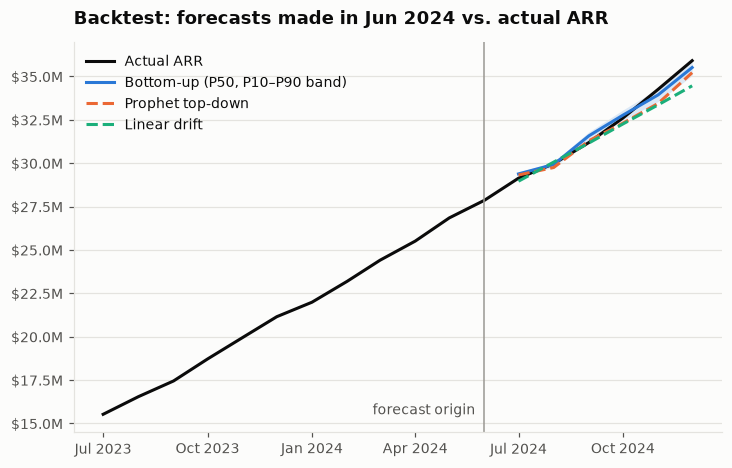

In [5]:
history = forecasting.monthly_arr(feat)
recent = history[history["ds"] > modeling.month_offset(backtest_as_of, -12)]

fig, ax = plt.subplots(figsize=(7.6, 4.6))
ax.fill_between(bt["month"], bt["bottom_up_p10"], bt["bottom_up_p90"], color=charts.SERIES[0], alpha=0.15, lw=0)
ax.plot(recent["ds"], recent["y"], color=charts.C["text"], label="Actual ARR")
lines = [("bottom_up_p50", "Bottom-up (P50, P10–P90 band)", charts.SERIES[0]),
         ("prophet_top_down", "Prophet top-down", charts.SERIES[1]),
         ("linear_drift", "Linear drift", charts.SERIES[2])]
for col, label, color in lines:
    ax.plot(bt["month"], bt[col], color=color, label=label, ls="--" if col != "bottom_up_p50" else "-")
ax.axvline(backtest_as_of, color=charts.REFERENCE, lw=1)
ax.annotate("forecast origin", (backtest_as_of, recent["y"].min()), xytext=(-6, 0), textcoords="offset points",
            ha="right", fontsize=9, color=charts.C["text_muted"])
charts.money(ax); charts.month_axis(ax)
ax.set_title(f"Backtest: forecasts made in {backtest_as_of:%b %Y} vs. actual ARR")
ax.legend(loc="upper left")
charts.save(fig, "forecast_backtest.png"); plt.show()

### Forward forecast and scenarios

In [6]:
scenario_fc = forecasting.bottom_up_forecast(feat, last_month, config.FORECAST_HORIZON, scenarios=config.SCENARIOS)
prophet_fc = forecasting.prophet_forecast(history, config.FORECAST_HORIZON)

end = scenario_fc[scenario_fc["month"] == scenario_fc["month"].max()].set_index("scenario")
start_arr = history["y"].iloc[-1]
print(f"ARR {last_month:%b %Y}: ${start_arr:,.0f}\n")
for name in ["Bear", "Base", "Bull"]:
    r = end.loc[name]
    print(f"{name:<5} {r['month']:%b %Y}: P50 ${r['arr_forecast']:,.0f}  (P10 ${r['arr_lower']:,.0f} – "
          f"P90 ${r['arr_upper']:,.0f})  growth {r['arr_forecast'] / start_arr - 1:+.1%}")
print(f"\nProphet top-down {prophet_fc['month'].max():%b %Y}: ${prophet_fc['yhat'].iloc[-1]:,.0f}")

base = scenario_fc[scenario_fc["scenario"] == "Base"]
print(f"\nBase case over 12 months: churned ARR ${base['arr_churned'].iloc[-1]:,.0f}, "
      f"new-business ARR ${base['arr_new'].iloc[-1]:,.0f}")

ARR Dec 2024: $35,910,348

Bear  Dec 2025: P50 $48,512,862  (P10 $47,053,258 – P90 $49,846,261)  growth +35.1%
Base  Dec 2025: P50 $51,625,066  (P10 $50,316,784 – P90 $52,822,950)  growth +43.8%
Bull  Dec 2025: P50 $54,864,908  (P10 $53,698,841 – P90 $55,875,559)  growth +52.8%

Prophet top-down Dec 2025: $50,342,591

Base case over 12 months: churned ARR $5,263,257, new-business ARR $19,314,586


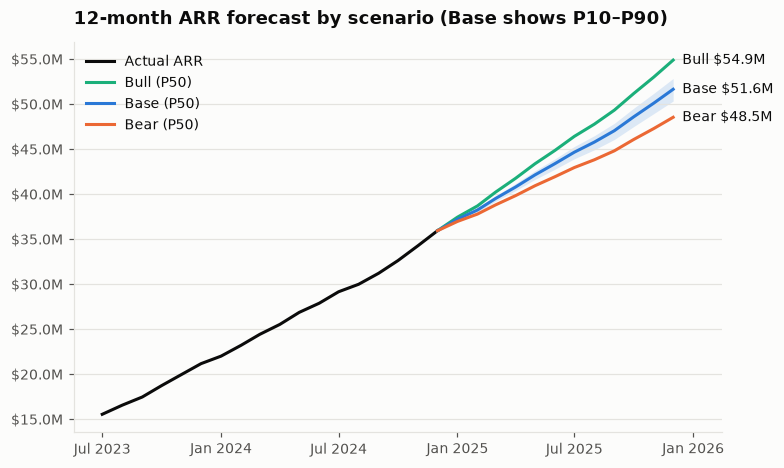

In [7]:
fig, ax = plt.subplots(figsize=(7.6, 4.6))
hist_recent = history[history["ds"] > modeling.month_offset(last_month, -18)]
ax.plot(hist_recent["ds"], hist_recent["y"], color=charts.C["text"], label="Actual ARR")
colors = {"Base": charts.SERIES[0], "Bear": charts.SERIES[1], "Bull": charts.SERIES[2]}
base = scenario_fc[scenario_fc["scenario"] == "Base"]
ax.fill_between(base["month"], base["arr_lower"], base["arr_upper"], color=colors["Base"], alpha=0.15, lw=0)
for name in ["Bull", "Base", "Bear"]:
    s = scenario_fc[scenario_fc["scenario"] == name]
    x = pd.concat([pd.Series([last_month]), s["month"]])
    y = pd.concat([pd.Series([start_arr]), s["arr_forecast"]])
    ax.plot(x, y, color=colors[name], label=f"{name} (P50)")
    charts.end_label(ax, s["month"].iloc[-1], s["arr_forecast"].iloc[-1], f"{name} ${s['arr_forecast'].iloc[-1] / 1e6:.1f}M")
charts.money(ax); charts.month_axis(ax, every=6)
ax.set_xlim(right=base["month"].max() + pd.Timedelta(days=75))
ax.set_title("12-month ARR forecast by scenario (Base shows P10–P90)")
ax.legend(loc="upper left")
charts.save(fig, "arr_forecast_scenarios.png"); plt.show()

In [8]:
hist_rows = history.rename(columns={"ds": "month", "y": "arr_forecast"}).assign(
    arr_lower=lambda d: d["arr_forecast"], arr_upper=lambda d: d["arr_forecast"], type="historical")
fc_rows = base[["month", "arr_forecast", "arr_lower", "arr_upper"]].assign(type="forecast")
arr_forecast = pd.concat([hist_rows, fc_rows], ignore_index=True)
arr_forecast = arr_forecast.merge(prophet_fc[["month", "yhat"]].rename(columns={"yhat": "prophet_top_down"}),
                                  on="month", how="left")

scenario_out = scenario_fc.assign(type="forecast")[
    ["month", "arr_forecast", "arr_lower", "arr_upper", "type", "scenario",
     "arr_existing", "arr_new", "arr_churned", "arr_mean"]]

# Scaling every monthly hazard by m turns 12-month survival S into roughly S**m.
risk = spark.table("gold_revenue_risk").toPandas()
scenario_risk = pd.concat([
    risk.assign(scenario=name,
                churn_probability=1 - (1 - risk["churn_probability"]) ** mult,
                revenue_risk=lambda d: d["churn_probability"] * d["arr"])
    for name, (mult, _) in config.SCENARIOS.items()
], ignore_index=True)[["customer_id", "segment", "plan_type", "arr", "churn_probability", "revenue_risk", "scenario"]]

for name, df in {"gold_arr_forecast": arr_forecast, "gold_scenario_forecast": scenario_out,
                 "gold_scenario_risk": scenario_risk, "gold_forecast_backtest": bt,
                 "gold_forecast_backtest_scores": bt_scores}.items():
    if "month" in df:
        df = df.assign(month=pd.to_datetime(df["month"]).dt.strftime("%Y-%m-%d"))
    spark_utils.write_table(spark, df, name)
    spark_utils.export_csv(spark, name)
print("Forecast tables written and exported to data/gold/")

Forecast tables written and exported to data/gold/


In [9]:
mlflow = spark_utils.setup_mlflow()
with mlflow.start_run(run_name="arr_forecast") as run:
    mlflow.set_tag("stage", "arr_forecast")
    mlflow.log_params({"horizon": config.FORECAST_HORIZON, "n_simulations": config.N_SIMULATIONS,
                       "signal_decay": config.SIGNAL_DECAY, "backtest_as_of": f"{backtest_as_of:%Y-%m}",
                       **{f"scenario_{k}": str(v) for k, v in config.SCENARIOS.items()}})
    for _, r in bt_scores.iterrows():
        mlflow.log_metric(f"backtest_mape_{r['method']}", float(r["mape"]))
    for name in ["Bear", "Base", "Bull"]:
        mlflow.log_metric(f"arr_12m_p50_{name.lower()}", float(end.loc[name, "arr_forecast"]))
    for img in ["forecast_backtest.png", "arr_forecast_scenarios.png"]:
        mlflow.log_artifact(str(config.IMAGES_DIR / img), "charts")
    print(f"MLflow run {run.info.run_id}")

MLflow run 1c0256d3b80f4dd5b2e293d5b53a68cf
